# De-embedding

This is a short tutorial on how de-embedding can be performed using scikit-rf. We will start by introducing the concept of de-embedding and why it is required, with a simple use-case scenario. Next, we will go through what kinds of de-embedding exist, and how to choose the right one for your application. Lastly, we will see how code can be written to quickly perform de-embedding on your s-parameter datasets.

## What is de-embedding and how does it differ from calibration?

Let's start with an example. Consider the measurement of integrated RF transistors built on a silicon wafer which are vital to the development of compact models for integrated circuit design. The typical measurement setup for such a scenario involves the use of RF probes that have a co-axial connector at one end, and a ground-signal-ground (GSG) probe tip at the other. This probe tip lands on GSG pads constructed on-wafer that provides access to the transistor under test. To measure an RF transistor, the actual device-under-test (DUT) is connected to GSG pads at two of the three terminals of the transistor via metal interconnects, while connecting the third terminal to RF ground. In common-source measurement configuration of a FET, this means that the Gate and Drain terminals are connected to the RF probes, and the Source terminal is grounded. Now, s-parameters are measured as a function of terminal voltages on the transistor.

But what is the calibration reference plane for this transistor s-parameter measurement? The effects of the cabling and probe transitions can be removed by performing a standard calibration using methods such as Thru-Reflect-Line (TRL) or Short-Open-Load-Thru (SOLT) to move the calibration reference to the probe tips, or in other words, to the GSG pads implemented on-wafer. The use of an Impedance Standard Substrates (ISS) provides a set of well-defined calibration standards that can be used to establish such a reference plane for measurement. However, there is still a substantial "test-fixture" involving metal interconnects that need to be removed before accessing the real terminals of the RF transistor whose measurement we actually want. **De-embedding refers to the removal of extraneous effects that a test fixture can have on the measurement of a device under test (DUT).** The figure below (obtained from [here](https://mos-ak.org/shanghai_2016/presentations/Bertrand_Ardouin_MOS-AK_Shanghai_2016.pdf)) shows an example of the "test-fixture" that often has to be removed in on-wafer measurement applications.

<img src="figures/onwafer_pads.png" alt="onwafer-pads" width="500">

The de-embedding process differs from calibration in that no well known standards are used either because they cannot exist in certain environments, or are not practical to implement given space and cost constraints. De-embedding uses several dummy structures that help remove unwanted test fixture effects, but does not provide enough information to deduce a complete error box network like those obtained using standard calibration techniques. Since the test fixture itself may contain various transitions and interconnects before reaching the DUT, de-embedding is useful when simple scalar port extension of the reference plane is not applicable.

For a basic introduction to this topic, refer [this article](http://na.support.keysight.com/faq/deembed.pdf).

## Open-Short De-embedding

In the last few decades of on-wafer RF measurements, the Open-Short de-embedding method has been the work horse of the RFIC industry where the frequencies of transistor operation have predominantly been in the range of a few gigahertz. As transistor measurements are extended to higher frequencies, more sophisticated de-embedding methods are required when the simplifying assumptions of Open-Short de-embedding break down. It is not easy to define a frequency limit up to which Open-Short de-embedding is valid because it depends on the layout techniques adopted in the design of on-wafer pad cages. If proper design techniques are adopted, Open-Short de-embedding should be applicable at least to 10 GHz if not more.

The accuracy of Open-Short de-embedding depends on the validity of assumption that the test-fixture parasitics are a combination of parallel conductances (in red) and series impedances (in orange) as shown in the figure below. The lumped element model is usually representative of an on-wafer test-fixture, because first there is the shunt pad capacitance in the GSG pads, followed by the series impedance of the interconnect lines. To move the reference plane of the measurements from the plane of calibration (the outer terminals of the network below) to the DUT, two dummy structures - Open and Short - are needed in addition to the DUT. To create an Open dummy, the DUT is simply removed from the test fixture, while the three terminals are shorted together to implement the Short dummy. With the help of these dummies, the real measurements of the DUT can be extracted.

<img src="figures/openshort.png" alt="openshort" width="500">

The detailed procedure of OpenShort de-embedding is shown in the figure below. The measurement result for the open dummy are clearly similar to those for parallel parasitics. The parallel parasitics are extracted simply by measuring the open dummies (step i). On the other hand, the short dummy includes both parallel and series parasitics. The series parasitics are extracted by subtracting the parallel parasitics from the short dummy in the Y-parameter domain (step ii). By subtracting the parallel and series parasitics from the DUT measurement results in the Y- and Z-parameter domains, respectively, a DUT without parasitic components can be extracted (step iii).

<img src="figures/OpenShortProcedure.svg" alt="OpenShortProcedure" width="700">

The reader is referred to [this detailed presentation](https://mos-ak.org/shanghai_2016/presentations/Bertrand_Ardouin_MOS-AK_Shanghai_2016.pdf) for intricate details regarding the design of on-wafer test structures and best practices. From here on, we will focus on explaining how the de-embedding class in scikit-rf works.

## De-embedding with Scikit-RF

In this section, let us build up a concrete example to demonstrate how de-embedding in scikit-rf works. Assume that the device under test is a 1nH inductor whose measurements we are interested in. Since this inductor must be placed in an on-wafer test-fixture, let us assume that the pad capacitance at each port is 25fF, the pad-pad capacitance is 10fF, and the resistance of interconnect lines from each pad are 2-ohms each. The resulting network whose measurements are available at the external reference plane P1-P2, is shown below. 

<img src="figures/ind_parasitics.png" alt="openshort-ckt" width="500">

The goal is to accurately extract the actual 1nH inductor by removing all other extraneous parasitic circuit elements.



In [1]:
import matplotlib.pyplot as plt
import numpy as np

import skrf as rf

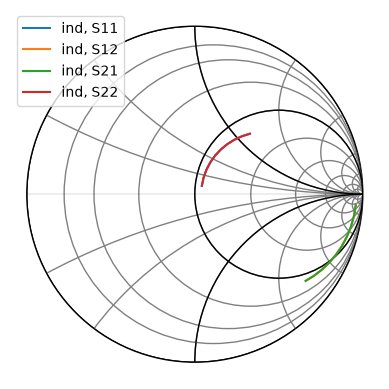

In [2]:
# Look at the raw inductor measurement with parasitics included
# From S11/S22, it is clear that it is not a pure inductance.
raw_ind = rf.data.ind
raw_ind.plot_s_smith()

If we were to extract inductance directly from this measurement, we will have an inductance value that changes with frequency, and the quality factor will also be influenced by the presence of parasitic resistors.

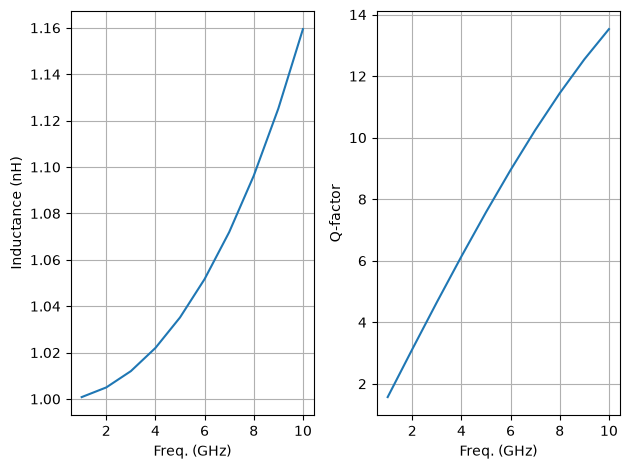

In [3]:
# plot the inductance and q-factor of the raw inductor measurement
Lraw_nH = 1e9 * np.imag(1/raw_ind.y[:,0,0])/2/np.pi/raw_ind.f
Qraw = np.abs(np.imag(1/raw_ind.y[:,0,0])/np.real(1/raw_ind.y[:,0,0]))

fig, (ax1, ax2) = plt.subplots(1,2)
ax1.plot(raw_ind.f*1e-9, Lraw_nH)
ax1.grid()
ax1.set_ylabel("Inductance (nH)")
ax1.set_xlabel("Freq. (GHz)")
ax2.plot(raw_ind.f*1e-9, Qraw)
ax2.grid()
ax2.set_ylabel("Q-factor")
ax2.set_xlabel("Freq. (GHz)")
fig.tight_layout()

To create an open dummy structure, the DUT, which is the 1nH inductor here is simply removed from the DUT test structure resulting in the circuit shown below.

<img src="figures/ind_open.png" alt="openckt" width="500">

To create a short dummy structure, the internal terminals of the test-fixture that would otherwise connect to the DUT are shorted to ground as shown below.

<img src="figures/ind_short.png" alt="shortckt" width="500">

In [4]:
# load in 2-ports short/open dummy networks
open_nw = rf.data.open_2p
short_nw = rf.data.short_2p

To perform Open-Short de-embedding with the available dummy measurements, we create a de-embedding object as an instance of the `OpenShort` class, while providing the open and short network objects as arguments to the de-embedding object creation.

To get the de-embedded network, we apply the `deembed` method on the network object on which we want to perform the de-embedding operation. This is shown below.

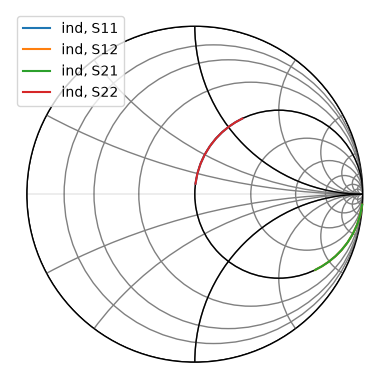

In [5]:
from skrf.calibration.deembedding import OpenShort

dm = OpenShort(dummy_open=open_nw, dummy_short=short_nw, name='tutorial')

actual_ind = dm.deembed(raw_ind)
actual_ind.plot_s_smith()

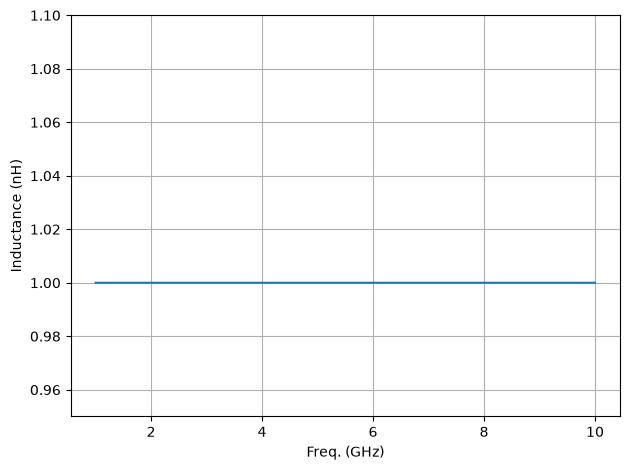

In [6]:
# plot the inductance of the de-embedded measurement
# we ignore plotting Q-factor here, because an ideal lossless inductor has infinite Q

Lactual_nH = 1e9 * np.imag(1/actual_ind.y[:,0,0])/2/np.pi/actual_ind.f

fig, ax1 = plt.subplots(1,1)
ax1.plot(actual_ind.f*1e-9, Lactual_nH)
ax1.grid()
ax1.set_ylim(0.95, 1.1)
ax1.set_ylabel("Inductance (nH)")
ax1.set_xlabel("Freq. (GHz)")
fig.tight_layout()

From the plot above, it is seen that the actual inductor value is accurately extracted even in the presence of unwanted parasitic elements due to proper de-embedding of the test-fixture.

## Through-only de-embedding

At higher frequencies above 10 GHz, the fringe capacitance of the open dummy and the parasitic inductance of the short dummy cause errors. For high frequencies, several methods using a through (thru) dummy have been proposed, such as `SplitPi`[[1](#ref1)], `SplitTee`[[2](#ref2)], `AdmittanceCancel`[[3](#ref3)], and `ImpedanceCancel`[[4](#ref4)]. The thru dummy is a direct connection of the left and right test pads. The example of the test device and thru dummy is shown in the figure below, where G and S indicate ground pads and signal pads.

<img src="figures/thru_micrograph.png" alt="thru_micrograph" width="500">

### Split methods

Split methods are based on lumped elements assumption as well as the open or short methods. The `SplitPi` and `SplitTee` methods assume that the embedding-networks are Π-network and T-network, respectively, as shown in the figure below. The values of the left and right parasitics (i.e. Z and Y) are extracted from the thru dummy. The parasitics are removed by multiplying by the inverse of the left and right ABCD matrix. **These methods can apply to only 2-port DUTs**.

<img src="figures/split_methods.svg" alt="split_methods" width="500">

### Immittance cancel methods

The `AdmittanceCancel` (a.k.a Mangan's method) and `ImpedanceCancel` methods are also based on lumped elements assumption as shown in the figure below. However, unlike the split methods, they do NOT directly calculate the immittance of the left and right parasitics. These methods de-embed the DUTs by left-right mirroring operation which is called 'swapping'. The `AdmittanceCancel` method consists of two steps. First, an matrix defined as 'H' is calculated by multiplying the ABCD matrix of the test device by inverse matrix of thru dummy as shown in figure(c). Then, the de-embedded Y matrix is obtained by taking the average of the left-right mirrored and un-mirrored Y-parameters of H. Similarly, in the case of the `ImpedanceCancel` method, it takes the average of the Z-parameters. **These methods can apply to only symmetric 2-port DUTs (i.e. S11=S22 and S12=S21)**, but more accurate than the split methods in the characterization of transmission lines at mmW frequencies. A comparison between the split methods and immittance cancel methods is described in [[4]](https://ieeexplore.ieee.org/document/7377897).

<img src="figures/immittance_cancel.svg" alt="immittance_cancel" width="500">

## Other De-embedding Methods

Other simple forms of de-embedding included in scikit-rf are `Open`, `Short` and `ShortOpen` methods, which may be applicable depending on the equivalent circuit of the parasitic network of the test-fixture. As an example, it may be desirable to only remove the pad contact resistance from the measurement for which `Short` de-embedding can be used. In certain measurements, only the pad capacitance might need to be removed, for which the `Open` de-embedding method would be more appropriate. To remove pad contact resistance and pad capacitance in one operation, the `ShortOpen` method would be the most suitable.

Many other sophisticated methods of de-embedding have been reported in literature to extend the accuracy of DUT measurements up to high frequencies. While they can be done using the network operations of scikit-rf, their inclusion as a built-in de-embedding class within the package is welcomed as an open-source contribution to the project.

## References

<div id="ref1"></div>[1]: [L. Nan et al., “Experimental Characterization of the Effect of Metal Dummy Fills on Spiral Inductors,” in 2007 IEEE Radio Frequency Integrated Circuits (RFIC) Symposium, Jun. 2007, pp. 307–310.](https://ieeexplore.ieee.org/document/4266437)

<div id="ref2"></div>[2]: [M. J. Kobrinsky et al., “Experimental validation of crosstalk simulations for on-chip interconnects using S-parameters,” IEEE Transactions on Advanced Packaging, vol. 28, no. 1, pp. 57–62, Feb. 2005.](https://ieeexplore.ieee.org/document/1391067)

<div id="ref3"></div>[3]: [A. M. Mangan et al., “De-embedding transmission line measurements for accurate modeling of IC designs,” IEEE Trans. Electron Devices, vol. 53, no. 2, pp. 235–241, Feb. 2006.](https://ieeexplore.ieee.org/document/1580859)

<div id="ref4"></div>[4]: [S. Amakawa et al., “Comparative analysis of on-chip transmission line de-embedding techniques,” in 2015 IEEE International Symposium on Radio-Frequency Integration Technology, Aug. 2015, pp. 91–93.](https://ieeexplore.ieee.org/document/7377897)